# Bài 6: Máy vectơ hỗ trợ (SVM)
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Lời giải theo `Lab06_SVM.pdf` của ThS. Nguyễn Thái Anh. Phần A gồm **5 bước thực hành**;
phần B gồm **6 bài tập**, kèm giải thích, kiểm chứng và hình minh họa như Lab5.

**Dữ liệu:** `sinh_vien.csv`, `sinh_vien_mo_rong.csv`, `hai_vang_trang.csv`; 24 điểm sinh bằng make_blobs và bộ chữ số load_digits.

**Cách chạy:** giải nén gói dữ liệu của lab để có `data/` cạnh notebook, rồi chọn
**Restart Kernel and Run All Cells**. Có thể đặt CSV trực tiếp cạnh notebook. Mở Jupyter từ
gốc repo hoặc thư mục lab đều được. Kết quả được nhúng trong notebook, hình lưu thêm vào `images/`.

**Cài thư viện:** `pip install numpy pandas matplotlib scikit-learn jupyter`.
Các bộ dữ liệu đóng gói trong scikit-learn không cần tải mạng. CSV/PDF/ZIP không đưa lên GitHub.

## 0. Chuẩn bị môi trường

Với thí nghiệm phân loại, chia 75% học / 25% kiểm tra với `random_state=17`, `stratify=y`, giống đề.
Chuẩn hoá được đặt trong pipeline để chỉ học thống kê từ từng tập học của CV.
Chọn tham số hoặc ngưỡng bằng tập học; tập kiểm tra dùng báo cáo các thí nghiệm đã định trong đề.
Vì cùng tập kiểm tra được dùng nhiều lần trong bài thực hành, không xem các kết quả là đánh giá
độc lập cho một hệ thống đã được lựa chọn sau nhiều thí nghiệm.

Lần kiểm tra này giới hạn BLAS/OpenMP ở 1 luồng để giảm dao động và chi phí chạy trên dữ liệu nhỏ; môi trường nhiều luồng có thể cho chênh lệch thời gian và sai số tối ưu số học.

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

THU_MUC_LAB = Path('06. SVM') if Path('06. SVM').is_dir() else Path('.')
THU_MUC_ANH = THU_MUC_LAB / 'images'
THU_MUC_ANH.mkdir(exist_ok=True)


def doc_csv(ten, cot_bat_buoc):
    for p in (THU_MUC_LAB / 'data' / ten, THU_MUC_LAB / ten):
        if p.is_file():
            df = pd.read_csv(p)
            assert set(cot_bat_buoc).issubset(df.columns), f'Sai cột trong {ten}'
            assert len(df) > 0 and np.isfinite(df[cot_bat_buoc].to_numpy(dtype=float)).all(), ten
            print(f'{ten}: {df.shape[0]} dòng, {df.shape[1]} cột; không thiếu giá trị ở cột dùng')
            return df
    raise FileNotFoundError(f'Thiếu {ten}: hãy giải nén gói dữ liệu vào {THU_MUC_LAB}/data/.')


def chia(X, y):
    return train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)


def luu_hinh(ten):
    plt.savefig(THU_MUC_ANH / ten, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def ve_bien(ax, mo_hinh, X, y, tieu_de):
    a = np.asarray(X)
    le = np.maximum(np.ptp(a, axis=0)*0.08, 0.1)
    xx, yy = np.meshgrid(np.linspace(a[:, 0].min()-le[0], a[:, 0].max()+le[0], 160),
                         np.linspace(a[:, 1].min()-le[1], a[:, 1].max()+le[1], 150))
    luoi = np.c_[xx.ravel(), yy.ravel()]
    if isinstance(X, pd.DataFrame):
        luoi = pd.DataFrame(luoi, columns=X.columns)
    zz = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#fed7d7', '#c3dafe'], alpha=0.8)
    ax.scatter(a[:, 0], a[:, 1], c=y, cmap='coolwarm_r', s=17, edgecolors='white', linewidths=0.3)
    ax.set_title(tieu_de)
    ax.set_xlabel(X.columns[0] if isinstance(X, pd.DataFrame) else 'x1')
    ax.set_ylabel(X.columns[1] if isinstance(X, pd.DataFrame) else 'x2')


plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110,
                     'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': 0.25})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__)
print('scikit-learn', sklearn.__version__, '| matplotlib', plt.matplotlib.__version__)

Python 3.11.9 | NumPy 1.26.4 | pandas 2.3.3
scikit-learn 1.8.0 | matplotlib 3.10.8


---
# Phần A — Bài thực hành
## Bước 1 — Đường có lề rộng nhất (Mục 2, `g1`)

SVM tuyến tính dùng $f(x)=w^Tx+b$; dấu của $f$ quyết định lớp. Hai đường $f=\pm1$ cách nhau
$2/\|w\|$. Tập ví dụ tách được dùng C=1000 để phạt mạnh vi phạm; C hữu hạn **không phải** ràng buộc
cứng tuyệt đối. Vectơ hỗ trợ ở bài này gần mép lề; với lề mềm, chúng còn có thể ở trong lề hoặc bị
phân loại sai. `decision_function` là điểm quyết định, không phải xác suất.

w=[-0.8313573  -0.35486826], b=4.820361; độ rộng lề=2.212565


,chi_so,x1,x2,nhan,f(x)
0,18,5.200993,4.217283,0,-1.000102
1,10,2.880864,4.016804,1,0.999897
2,13,3.587647,2.360141,1,1.000205


Min |f| của các điểm không hỗ trợ: 1.05891515102235
Học chỉ trên vectơ hỗ trợ: [-0.83132871 -0.35519907] 4.821417907152539


,x1,x2,f,lop
0,3.0,3.0,1.261684,1
1,5.0,4.5,-0.933333,0


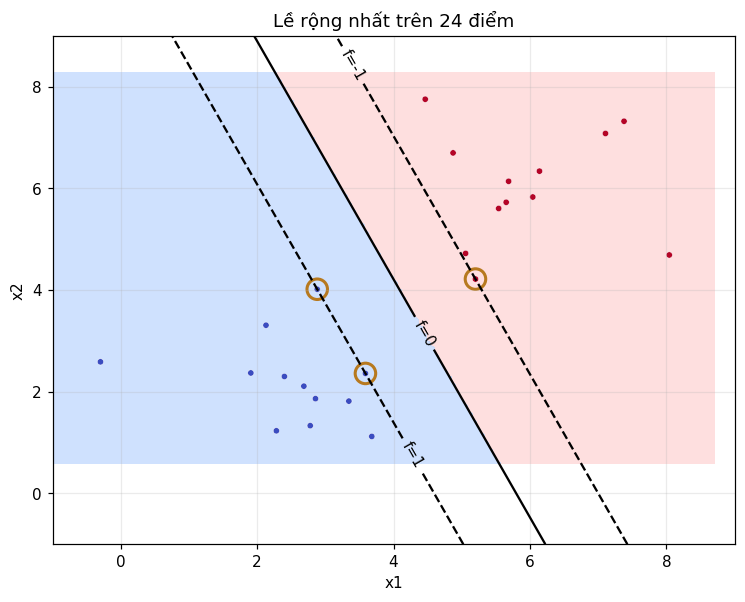

In [2]:
from sklearn.datasets import make_blobs, make_classification
from sklearn.svm import LinearSVC

X_blob, y_blob = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0)
y_blob = 1-y_blob
svm_blob = SVC(kernel='linear', C=1000).fit(X_blob, y_blob)
w, b = svm_blob.coef_[0], svm_blob.intercept_[0]
do_rong_le = 2/np.linalg.norm(w)
print(f'w={w}, b={b:.6f}; độ rộng lề={do_rong_le:.6f}')
sv = svm_blob.support_
display(pd.DataFrame({'chi_so': sv, 'x1': X_blob[sv, 0], 'x2': X_blob[sv, 1],
                      'nhan': y_blob[sv], 'f(x)': svm_blob.decision_function(X_blob[sv])}))
ngoai = np.setdiff1d(np.arange(24), sv)
print('Min |f| của các điểm không hỗ trợ:', abs(svm_blob.decision_function(X_blob[ngoai])).min())
chi_sv = SVC(kernel='linear', C=1000).fit(X_blob[sv], y_blob[sv])
print('Học chỉ trên vectơ hỗ trợ:', chi_sv.coef_[0], chi_sv.intercept_[0])
moi_blob = np.array([[3., 3.], [5., 4.5]])
display(pd.DataFrame(moi_blob, columns=['x1', 'x2']).assign(
    f=svm_blob.decision_function(moi_blob), lop=svm_blob.predict(moi_blob)))
assert np.allclose(X_blob @ w+b, svm_blob.decision_function(X_blob))

fig, ax = plt.subplots(figsize=(8, 6))
ve_bien(ax, svm_blob, X_blob, y_blob, 'Lề rộng nhất trên 24 điểm')
xx, yy = np.meshgrid(np.linspace(-1, 9, 160), np.linspace(-1, 9, 160))
cs = ax.contour(xx, yy, svm_blob.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape),
                levels=[-1, 0, 1], colors='black', linestyles=['--', '-', '--'])
ax.clabel(cs, fmt='f=%.0f')
ax.scatter(X_blob[sv, 0], X_blob[sv, 1], s=180, facecolors='none', edgecolors='#b7791f', linewidths=2)
luu_hinh('hinh1_le_va_vecto_ho_tro.png')

**Nhận xét từ lần chạy đã kiểm tra:** Lề rộng **2.2126**, có **3 vectơ hỗ trợ**. Hệ số w≈(-0.8314,-0.3549), b≈4.8204. Các điểm không hỗ trợ có |f| nhỏ nhất 1.0589>1; học lại chỉ trên 3 điểm hỗ trợ gần như giữ nguyên biên.

**Đọc kết quả:** so hệ số học lại với hệ số ban đầu ở độ chính xác phù hợp sai số tối ưu.
Đường biên được quyết định bởi các điểm sát nó; các điểm xa ở ví dụ tách được không làm đổi
nghiệm tối ưu. Công thức độ rộng lề chỉ áp dụng cho biểu diễn tuyến tính đang xét.

## Bước 2 — Lề mềm, C và chuẩn hoá (Mục 3, `g2`)

C nhỏ cho phép nhiều vi phạm hơn để có biên đơn giản; C lớn phạt vi phạm nặng hơn.
Độ rộng lề sau StandardScaler được đo trong **không gian chuẩn hoá**, không phải đơn vị gốc.

sinh_vien.csv: 120 dòng, 3 cột; không thiếu giá trị ở cột dùng


,C,so_vecto,do_rong_le_chuan,acc_hoc,acc_kiem_tra
0,0.01,74,3.8414,0.8556,0.8667
1,0.10,44,1.7033,0.8889,0.9000
2,1.00,31,1.2879,0.8778,0.9000
3,10.00,28,1.0648,0.9000,0.9000
4,100.00,27,1.0496,0.9000,0.9000


sinh_vien_mo_rong.csv: 120 dòng, 4 cột; không thiếu giá trị ở cột dùng


,cach,accuracy
0,Không chuẩn hoá,0.6
1,Có chuẩn hoá,0.9


Baseline luôn đoán qua: 0.6


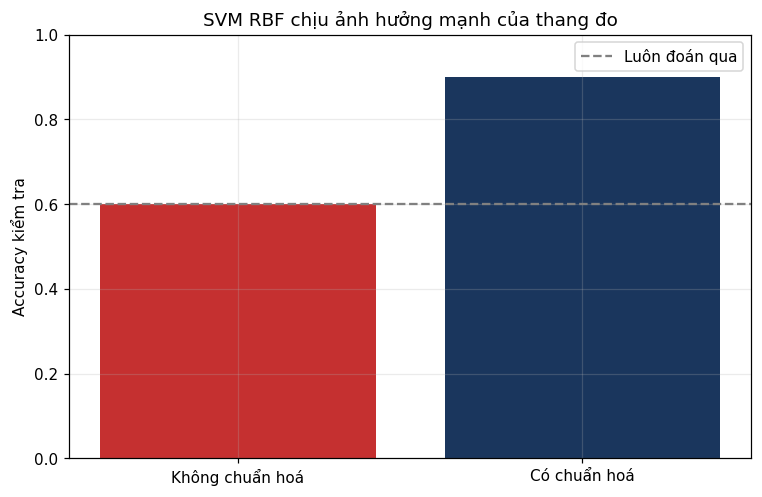

In [3]:
svien = doc_csv('sinh_vien.csv', ['gio_on', 'diem_giua_ky', 'qua_mon'])
X_sv, y_sv = svien[['gio_on', 'diem_giua_ky']], svien['qua_mon']
Xsv_tr, Xsv_te, ysv_tr, ysv_te = chia(X_sv, y_sv)
bang_c = []
for c in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel='linear', C=c)).fit(Xsv_tr, ysv_tr)
    bang_c.append({'C': c, 'so_vecto': len(mh[-1].support_), 'do_rong_le_chuan': 2/np.linalg.norm(mh[-1].coef_[0]),
                   'acc_hoc': mh.score(Xsv_tr, ysv_tr), 'acc_kiem_tra': mh.score(Xsv_te, ysv_te)})
display(pd.DataFrame(bang_c).round(4))
sv3 = doc_csv('sinh_vien_mo_rong.csv', ['gio_on', 'diem_giua_ky', 'chi_tieu', 'qua_mon'])
X3_tr, X3_te, y3_tr, y3_te = chia(sv3[['gio_on', 'diem_giua_ky', 'chi_tieu']], sv3['qua_mon'])
bang_chuan = []
for ten, mh in [('Không chuẩn hoá', SVC()), ('Có chuẩn hoá', make_pipeline(StandardScaler(), SVC()))]:
    mh.fit(X3_tr, y3_tr)
    bang_chuan.append({'cach': ten, 'accuracy': mh.score(X3_te, y3_te)})
display(pd.DataFrame(bang_chuan))
print('Baseline luôn đoán qua:', y3_te.mean())
plt.figure()
plt.bar([r['cach'] for r in bang_chuan], [r['accuracy'] for r in bang_chuan], color=['#c53030', '#1a365d'])
plt.axhline(y3_te.mean(), linestyle='--', color='gray', label='Luôn đoán qua')
plt.ylim(0, 1); plt.ylabel('Accuracy kiểm tra'); plt.legend()
plt.title('SVM RBF chịu ảnh hưởng mạnh của thang đo'); luu_hinh('hinh2_chuan_hoa.png')

**Nhận xét từ lần chạy đã kiểm tra:** Khi C tăng 0.01→100, số vectơ hỗ trợ giảm 74→27 và lề chuẩn hoá giảm 3.8414→1.0496. Trên dữ liệu ba cột, không chuẩn hoá đạt **0.6000**, chuẩn hoá đạt **0.9000**; accuracy không tăng đều theo C.

**Giải thích:** cột chi tiêu có thang đo lớn chi phối khoảng cách trong kernel RBF. Chuẩn hoá
trong pipeline khắc phục chênh lệch thang đo và tránh học thống kê từ tập kiểm tra.
Không kết luận C càng lớn thì accuracy luôn tăng: chất lượng phải được kiểm chứng bằng CV.

## Bước 3 — Nâng chiều bằng tay và kernel (Mục 4, `g3`)

Lớp 1 nằm giữa trục x không thể tách hoàn hảo với một ngưỡng. Thêm $x^2$ cho phép đường thẳng
trong không gian mới tạo hai mốc trên trục gốc. Kernel tính tích vô hướng trong không gian đặc
trưng mà không cần xây toàn bộ các toạ độ đó. Hai cột vầng trăng có thang đo gần nhau;
thực hành cơ sở giữ dữ liệu gốc để đối chiếu đúng đề.

Một ngưỡng (hướng <= theo đề): 0.7142857142857143
Thêm x²: 1.0
hai_vang_trang.csv: 300 dòng, 3 cột; không thiếu giá trị ở cột dùng


,mo_hinh,accuracy
0,SVM tuyến tính,0.8667
1,Poly bậc 3,0.8667
2,SVM RBF,0.9200
3,Logistic,0.8533
4,KNN k=13,0.9200


Số vectơ hỗ trợ RBF: 89 / 225


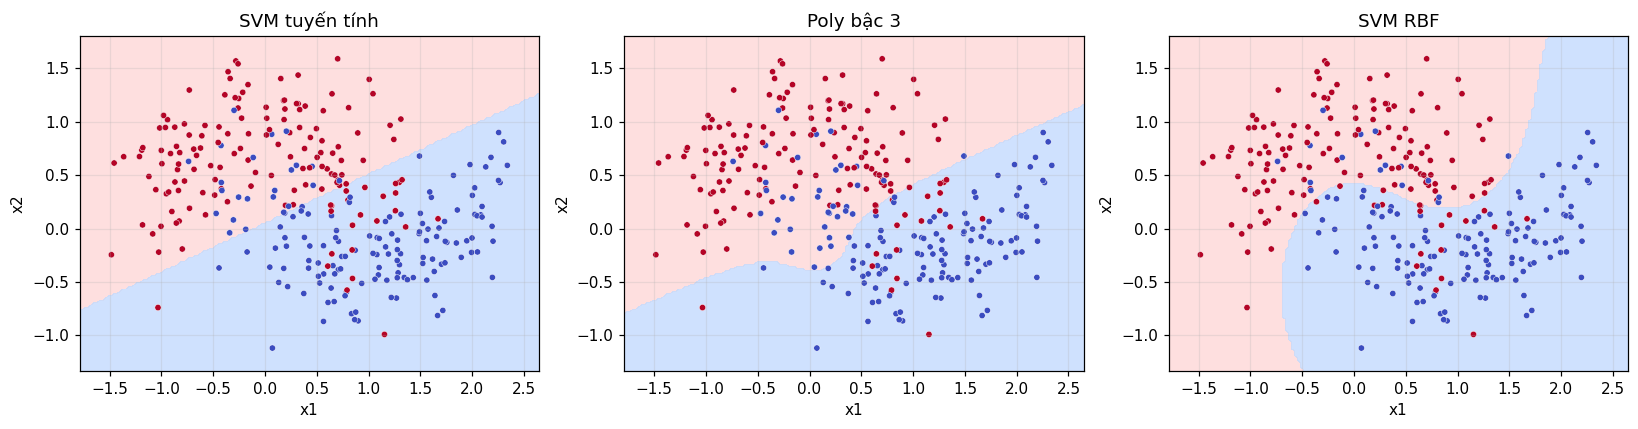

In [4]:
x = np.array([-4, -3.4, -2.8, -2.2, -1.2, -.7, -.2, .3, .8, 1.3, 2.3, 2.9, 3.5, 4.])
y_1d = (abs(x)<1.8).astype(int)
diem_nguong = max(((x<=t).astype(int)==y_1d).mean() for t in x)
nang_chieu = SVC(kernel='linear', C=1000).fit(np.c_[x, x*x], y_1d)
print('Một ngưỡng (hướng <= theo đề):', diem_nguong)
print('Thêm x²:', nang_chieu.score(np.c_[x, x*x], y_1d))
trang = doc_csv('hai_vang_trang.csv', ['x1', 'x2', 'nhan'])
X_trang, y_trang = trang[['x1', 'x2']], trang['nhan']
Xt_tr, Xt_te, yt_tr, yt_te = chia(X_trang, y_trang)
mo_hinh_trang = {'SVM tuyến tính': SVC(kernel='linear'), 'Poly bậc 3': SVC(kernel='poly', degree=3),
                 'SVM RBF': SVC(), 'Logistic': LogisticRegression(), 'KNN k=13': KNeighborsClassifier(13)}
bang_kernel = []
for ten, mh in mo_hinh_trang.items():
    mh.fit(Xt_tr, yt_tr); bang_kernel.append({'mo_hinh': ten, 'accuracy': mh.score(Xt_te, yt_te)})
display(pd.DataFrame(bang_kernel).round(4))
print('Số vectơ hỗ trợ RBF:', len(mo_hinh_trang['SVM RBF'].support_), '/', len(Xt_tr))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ten in zip(axes, ['SVM tuyến tính', 'Poly bậc 3', 'SVM RBF']):
    ve_bien(ax, mo_hinh_trang[ten], X_trang, y_trang, ten)
plt.tight_layout(); luu_hinh('hinh3_cac_kernel.png')

**Nhận xét từ lần chạy đã kiểm tra:** Một ngưỡng theo hướng đề thử đạt 10/14 điểm (0.7143); thêm x² đạt 1.0000 trên ví dụ. Với hai vầng trăng, SVM tuyến tính đạt **0.8667**, RBF **0.9200**, KNN k=13 cũng đạt 0.9200.

## Bước 4 — Gamma và dò lưới C, gamma (Mục 5, `g4`)

RBF dùng $K(x,z)=\exp(-\gamma\|x-z\|^2)$. Gamma lớn làm ảnh hưởng cục bộ hơn, biên dễ bám nhiễu.
Bảng kiểm tra theo gamma chỉ minh họa theo đề; cặp cuối cùng được chọn bằng GridSearchCV trên tập học.

,gamma,acc_hoc,acc_kiem_tra,so_vecto
0,0.1,0.8356,0.8533,113
1,1.0,0.8711,0.9200,88
2,10.0,0.8978,0.9067,128
3,100.0,0.9422,0.8133,217


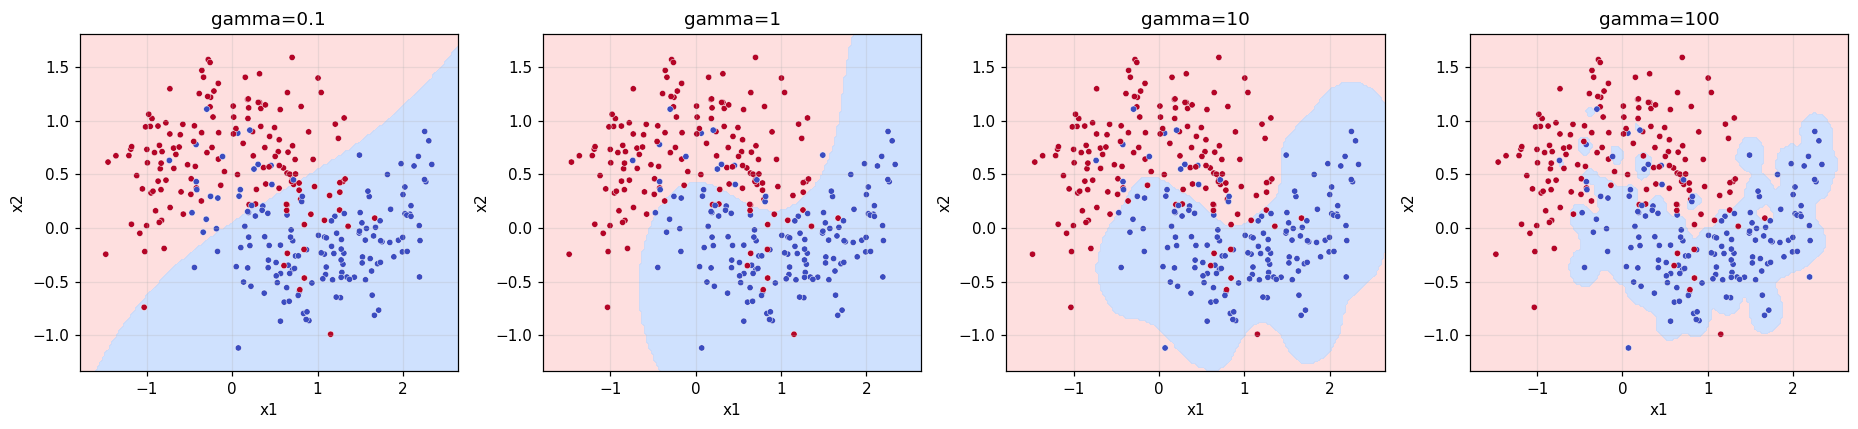

gamma,0.01,0.10,1.00,10.00
C,,,,
0.1,0.6578,0.8044,0.8444,0.8578
1.0,0.8044,0.8178,0.8667,0.8667
10.0,0.8178,0.8400,0.8711,0.8311
100.0,0.8178,0.8533,0.8711,0.7467


Tốt nhất: {'C': 10, 'gamma': 1} CV: 0.8711111111111112 Kiểm tra: 0.92


In [5]:
bang_gamma = []
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, g in zip(axes, [0.1, 1, 10, 100]):
    mh = SVC(gamma=g).fit(Xt_tr, yt_tr)
    bang_gamma.append({'gamma': g, 'acc_hoc': mh.score(Xt_tr, yt_tr), 'acc_kiem_tra': mh.score(Xt_te, yt_te),
                       'so_vecto': len(mh.support_)})
    ve_bien(ax, mh, X_trang, y_trang, f'gamma={g}')
display(pd.DataFrame(bang_gamma).round(4))
plt.tight_layout(); luu_hinh('hinh4_gamma.png')
tim_rbf = GridSearchCV(SVC(), {'C': [.1, 1, 10, 100], 'gamma': [.01, .1, 1, 10]}, cv=5, scoring='accuracy')
tim_rbf.fit(Xt_tr, yt_tr)
bang_luoi = pd.DataFrame(tim_rbf.cv_results_['params']).assign(diem=tim_rbf.cv_results_['mean_test_score'])
display(bang_luoi.pivot(index='C', columns='gamma', values='diem').round(4))
print('Tốt nhất:', tim_rbf.best_params_, 'CV:', tim_rbf.best_score_, 'Kiểm tra:', tim_rbf.score(Xt_te, yt_te))

**Nhận xét từ lần chạy đã kiểm tra:** Gamma=100 cho accuracy học **0.9422** nhưng kiểm tra chỉ **0.8133**, dấu hiệu quá khớp. Lưới chọn **C=10, gamma=1**, CV **0.8711**, kiểm tra **0.9200**; đây là cặp được chọn từ CV, không từ điểm kiểm tra.

## Bước 5 — Nhận dạng chữ số (Mục 6, `g5`)

1.797 ảnh 8×8, mỗi hàng có 64 độ sáng trong [0,16]. Giữ SVM RBF không chuẩn hoá làm mô hình cơ sở
như đề; so thêm SVM chuẩn hoá, KNN và logistic trên cùng lần chia phân tầng.

In [6]:
X_digits, y_digits = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = chia(X_digits, y_digits)
print(X_digits.shape, 'miền sáng:', (X_digits.min(), X_digits.max()), 'số ảnh mỗi lớp:', np.bincount(y_digits))
svm_digits = SVC().fit(Xd_tr, yd_tr)
du_digits = svm_digits.predict(Xd_te)
sai_digits = np.flatnonzero(du_digits!=yd_te)
bang_digits = [{'mo_hinh': 'SVM RBF', 'accuracy': accuracy_score(yd_te, du_digits)}]
for ten, mh in [('SVM chuẩn hoá', make_pipeline(StandardScaler(), SVC())), ('KNN k=5', KNeighborsClassifier()),
                ('Logistic chuẩn hoá', make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))]:
    mh.fit(Xd_tr, yd_tr); bang_digits.append({'mo_hinh': ten, 'accuracy': mh.score(Xd_te, yd_te)})
display(pd.DataFrame(bang_digits).round(4))
print('Vectơ hỗ trợ:', len(svm_digits.support_), '/', len(Xd_tr), '; số ảnh sai:', len(sai_digits))

(1797, 64) miền sáng: (0.0, 16.0) số ảnh mỗi lớp: [178 182 177 183 181 182 181 179 174 180]


,mo_hinh,accuracy
0,SVM RBF,0.9911
1,SVM chuẩn hoá,0.9778
2,KNN k=5,0.9867
3,Logistic chuẩn hoá,0.9711


Vectơ hỗ trợ: 626 / 1347 ; số ảnh sai: 4


**Nhận xét từ lần chạy đã kiểm tra:** SVM RBF đúng **446/450 ảnh (0.9911)**; KNN 0.9867, logistic chuẩn hoá 0.9711. Chuẩn hoá SVM cho 0.9778 ở dữ liệu này: mọi pixel đã cùng miền [0,16], nên chuẩn hoá không mặc định cải thiện.

---
# Phần B — Bài tập
## Bài tập 1 — Tính tay khoảng cách tới đường biên

Tính bằng phép nhân/cộng với hệ số đầy đủ, tránh làm tròn w,b trước khi tính. Khi $|f|=1$,
khoảng cách là $1/\|w\|$, đúng bằng một nửa lề $2/\|w\|$.

In [7]:
diem_bt1 = np.vstack([moi_blob, X_blob[sv]])
f_tay = diem_bt1[:, 0]*w[0]+diem_bt1[:, 1]*w[1]+b
khoang_cach = abs(f_tay)/np.sqrt(w[0]**2+w[1]**2)
display(pd.DataFrame(diem_bt1, columns=['x1', 'x2']).assign(f_tay=f_tay, khoang_cach=khoang_cach))
print('Nửa lề:', do_rong_le/2)
assert np.allclose(khoang_cach[2:], do_rong_le/2, atol=2e-3)

,x1,x2,f_tay,khoang_cach
0,3.000000,3.000000,1.261684,1.395779
1,5.000000,4.500000,-0.933333,1.032530
2,5.200993,4.217283,-1.000102,1.106396
3,2.880864,4.016804,0.999897,1.106169
4,3.587647,2.360141,1.000205,1.106509


Nửa lề: 1.1062823884231796


**Nhận xét từ lần chạy đã kiểm tra:** Khoảng cách của (3,3) là **1.3958**, của (5,4.5) là **1.0325**. Ba vectơ hỗ trợ cách biên khoảng **1.1063**, bằng nửa lề; sai lệch cỡ 0.0002 là sai số tối ưu số học.

## Bài tập 2 — Thêm điểm xa và điểm gần biên

Thử riêng từng điểm mới, không tích lũy cả hai. Điểm mới nằm xa về phía lớp 1 thường không trở
thành vectơ hỗ trợ; điểm lớp 1 chạm vùng biên buộc bài toán tối ưu phải điều chỉnh.

,diem_them,w1,w2,b,diem_moi_la_sv,chenh_w,chenh_b
0,"[-1.0, -1.0]",-0.831357,-0.354868,4.820361,False,0.000000,0.000000
1,"[4.5, 4.0]",-2.603014,-0.806843,15.940939,True,1.828401,11.120578


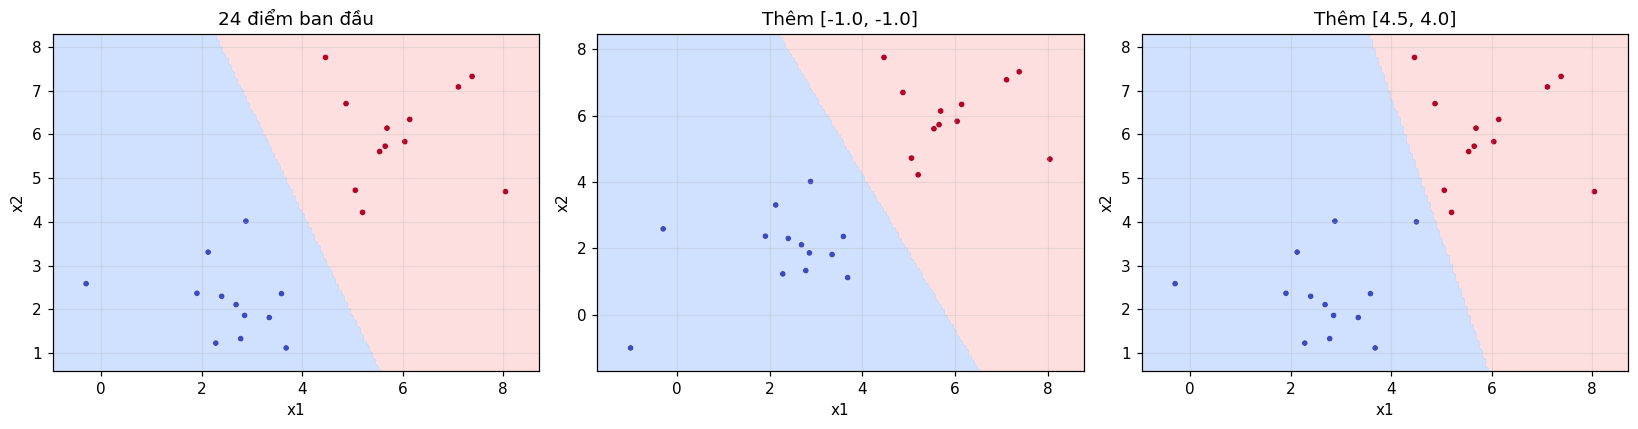

In [8]:
bang_them = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ve_bien(axes[0], svm_blob, X_blob, y_blob, '24 điểm ban đầu')
for ax, diem in zip(axes[1:], [[-1., -1.], [4.5, 4.]]):
    Xm = np.vstack([X_blob, diem]); ym = np.r_[y_blob, 1]
    mh = SVC(kernel='linear', C=1000).fit(Xm, ym)
    bang_them.append({'diem_them': str(diem), 'w1': mh.coef_[0,0], 'w2': mh.coef_[0,1],
                      'b': mh.intercept_[0], 'diem_moi_la_sv': 24 in mh.support_,
                      'chenh_w': np.linalg.norm(mh.coef_[0]-w), 'chenh_b': abs(mh.intercept_[0]-b)})
    ve_bien(ax, mh, Xm, ym, f'Thêm {diem}')
display(pd.DataFrame(bang_them).round(6))
plt.tight_layout(); luu_hinh('hinh5_them_mot_diem.png')

**Nhận xét từ lần chạy đã kiểm tra:** Thêm (-1,-1) không làm đổi w,b và điểm mới không là vectơ hỗ trợ. Thêm (4.5,4) làm w≈(-2.6030,-0.8068), b≈15.9409 và điểm mới trở thành vectơ hỗ trợ. Chỉ lần thêm điểm sát vùng biên làm đường quyết định đổi rõ rệt.

## Bài tập 3 — Kernel đa thức

Dò C riêng cho bậc 2, 3, 4 bằng CV, pipeline có chuẩn hoá như yêu cầu. Bậc tốt nhất chọn theo
CV, rồi so điểm kiểm tra với RBF cơ sở; hai quy trình tiền xử lý khác nhau nên nêu rõ khi so.

In [9]:
bang_poly = []
for bac in [2, 3, 4]:
    tim = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='poly', degree=bac)),
                        {'svc__C': [.1, 1, 10, 100]}, cv=5, scoring='accuracy').fit(Xt_tr, yt_tr)
    bang_poly.append({'bac': bac, 'C': tim.best_params_['svc__C'], 'cv': tim.best_score_,
                      'accuracy_kiem_tra': tim.score(Xt_te, yt_te)})
bang_poly = pd.DataFrame(bang_poly); display(bang_poly.round(4))
dong = bang_poly.loc[bang_poly['cv'].idxmax()]
print('Bậc tốt nhất theo CV:', int(dong['bac']), '; kiểm tra:', dong['accuracy_kiem_tra'])
print('RBF mục 5 kiểm tra:', tim_rbf.score(Xt_te, yt_te))

,bac,C,cv,accuracy_kiem_tra
0,2,1,0.5422,0.5067
1,3,1,0.8178,0.8267
2,4,100,0.5156,0.4800


Bậc tốt nhất theo CV: 3 ; kiểm tra: 0.8266666666666667
RBF mục 5 kiểm tra: 0.92


**Nhận xét từ lần chạy đã kiểm tra:** Bậc **3**, C=1 tốt nhất theo CV (0.8178); kiểm tra **0.8267**, không vượt RBF 0.9200. Bậc 2/4 chỉ quanh mức đoán ngẫu nhiên ở cấu hình mặc định coef0=0; tăng bậc không bảo đảm mô tả hình dạng dữ liệu tốt hơn.

## Bài tập 4 — Dò lưới mịn

Giữ cách tiền xử lý của lưới RBF phần A; thử C=[3,10,30], gamma=[0.3,1,3]. Lợi ích của lưới
mịn phải đọc từ CV, không dùng điểm kiểm tra để quyết định tiếp tục tinh chỉnh.

In [10]:
tim_min = GridSearchCV(SVC(), {'C': [3, 10, 30], 'gamma': [.3, 1, 3]}, cv=5, scoring='accuracy').fit(Xt_tr, yt_tr)
print('Lưới mịn:', tim_min.best_params_, 'CV:', tim_min.best_score_, 'Kiểm tra:', tim_min.score(Xt_te, yt_te))
print('Mức tăng CV so với lưới ban đầu:', tim_min.best_score_-tim_rbf.best_score_)
display(pd.DataFrame(tim_min.cv_results_)[['param_C', 'param_gamma', 'mean_test_score', 'std_test_score']].round(4))

Lưới mịn: {'C': 30, 'gamma': 1} CV: 0.8755555555555556 Kiểm tra: 0.92
Mức tăng CV so với lưới ban đầu: 0.004444444444444473


,param_C,param_gamma,mean_test_score,std_test_score
0,3,0.3,0.8533,0.0267
1,3,1.0,0.8711,0.0089
2,3,3.0,0.8667,0.0141
3,10,0.3,0.8489,0.0218
4,10,1.0,0.8711,0.0089
5,10,3.0,0.8667,0.0281
6,30,0.3,0.8622,0.0166
7,30,1.0,0.8756,0.0178
8,30,3.0,0.8533,0.0361


**Nhận xét từ lần chạy đã kiểm tra:** Lưới mịn chọn **C=30, gamma=1**, CV **0.8756**, tăng 0.0044 so với lưới ban đầu; kiểm tra vẫn **0.9200**. Dò mịn có lợi nhỏ trên CV nhưng không cải thiện điểm kiểm tra của lần chia này.

## Bài tập 5 — Những chữ số bị nhầm

Ma trận: hàng là nhãn thật, cột là nhãn đoán. Lưu riêng **từng ảnh sai** theo yêu cầu.
Một ảnh 8×8 có ít chi tiết; nét mờ hoặc hình dáng giống lớp khác có thể gây nhầm.
Đây là giải thích hình ảnh định tính, không khẳng định nguyên nhân bên trong mô hình.

,0,1,2,3,4,5,6,7,8,9
0,45,0,0,0,0,0,0,0,0,0
1,0,46,0,0,0,0,0,0,0,0
2,0,0,44,0,0,0,0,0,0,0
3,0,0,0,46,0,0,0,0,0,0
4,0,0,0,0,44,0,0,0,1,0
5,0,0,0,0,0,46,0,0,0,0
6,0,0,0,0,0,0,45,0,0,0
7,0,0,0,0,0,0,0,44,0,1
8,0,1,0,0,0,0,0,0,42,0
9,0,0,0,1,0,0,0,0,0,44


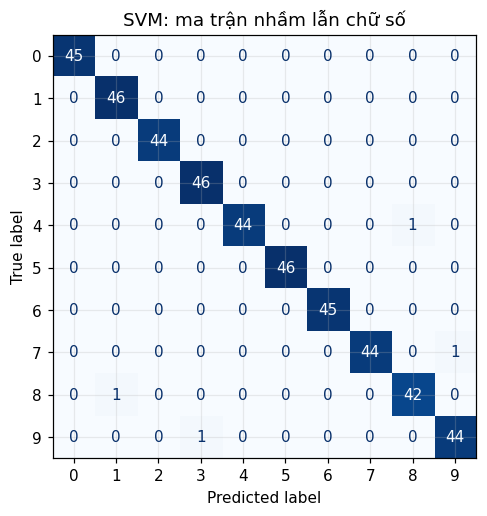

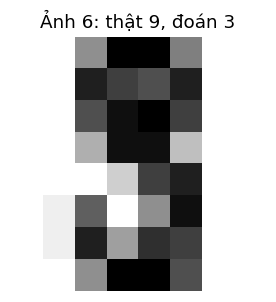

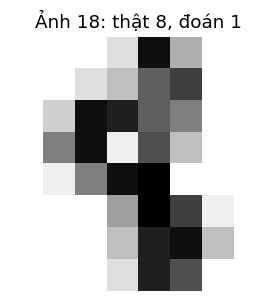

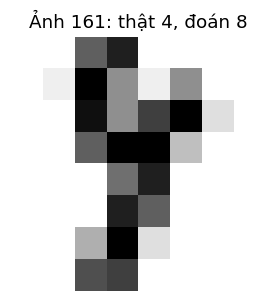

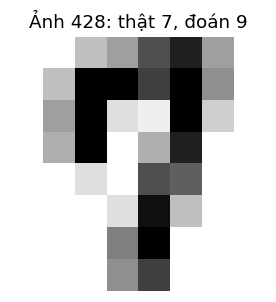

,chi_so_kiem_tra,that,doan
0,6,9,3
1,18,8,1
2,161,4,8
3,428,7,9


In [11]:
cm_digits = confusion_matrix(yd_te, du_digits, labels=np.arange(10))
display(pd.DataFrame(cm_digits, index=range(10), columns=range(10)))
ConfusionMatrixDisplay(cm_digits, display_labels=range(10)).plot(cmap='Blues', colorbar=False)
plt.title('SVM: ma trận nhầm lẫn chữ số'); luu_hinh('hinh6_ma_tran_chu_so.png')
for i in sai_digits:
    plt.figure(figsize=(3, 3)); plt.imshow(Xd_te[i].reshape(8,8), cmap='gray_r')
    plt.title(f'Ảnh {i}: thật {yd_te[i]}, đoán {du_digits[i]}'); plt.axis('off')
    luu_hinh(f'chu_so_sai_{i}_that_{yd_te[i]}_doan_{du_digits[i]}.png')
display(pd.DataFrame({'chi_so_kiem_tra': sai_digits, 'that': yd_te[sai_digits], 'doan': du_digits[sai_digits]}))

**Nhận xét từ lần chạy đã kiểm tra:** Bốn cặp nhầm (thật→đoán) là **9→3, 8→1, 4→8, 7→9**. Ở ảnh 9→3, nét trái của vòng trên không rõ; ảnh 8→1 có nét dọc dày và vòng hẹp. Độ phân giải 8×8 làm các dấu phân biệt dễ mất. Đây là nhận xét thị giác, không phải chứng minh nhân quả về quyết định của SVM.

## Bài tập 6 — Thời gian học trên dữ liệu lớn

Sinh đúng `make_classification(n_samples=n, n_features=20, random_state=0)` cho mỗi n.
Chỉ đo `.fit`, giữ SVC() và LinearSVC() mặc định; `random_state=0` của LinearSVC cố định phần
ngẫu nhiên, không thay kiểu bài toán. Đo hai lần sau khi làm nóng thư viện, lấy trung vị để giảm
nhiễu thời gian. Đây là so hai mô hình kernel RBF và tuyến tính, không chỉ hai bộ giải tương đương.

,n,SVC_giay,LinearSVC_giay,ty_le_n,ty_le_SVC_giay,ty_le_LinearSVC_giay
0,2000,0.0196,0.0015,NaN,NaN,NaN
1,5000,0.0928,0.0033,2.5,4.7263,2.2271
2,10000,1.1716,0.0067,2.0,12.6249,2.0164
3,20000,3.2398,0.0122,2.0,2.7652,1.8410


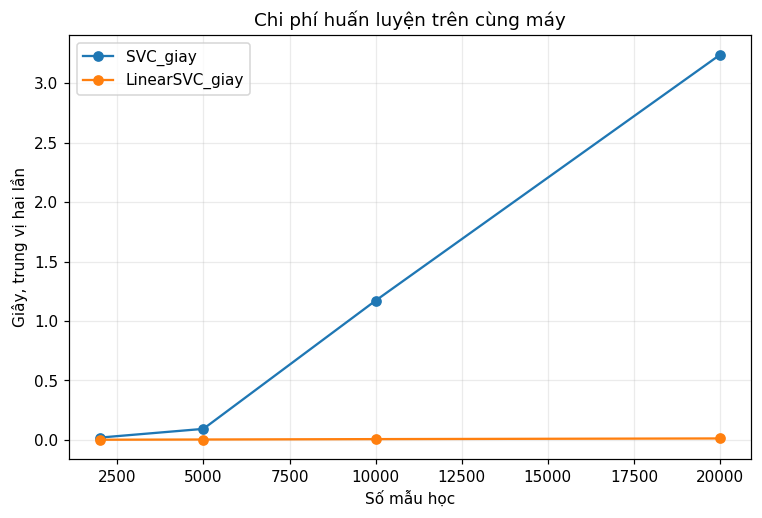

**Nhận xét định lượng:** 5000→10000: SVC ×12.62, LinearSVC ×2.02; 10000→20000: SVC ×2.77, LinearSVC ×1.84. Hai bước cuối mới là tăng gấp đôi; 2.000→5.000 tăng 2,5 lần.

In [12]:
# Làm nóng bên ngoài khoảng thời gian đo.
Xa, ya = make_classification(n_samples=100, n_features=20, random_state=0)
SVC().fit(Xa, ya); LinearSVC(random_state=0).fit(Xa, ya)
bang_tg = []
for n in [2000, 5000, 10000, 20000]:
    Xn, yn = make_classification(n_samples=n, n_features=20, random_state=0)
    dong = {'n': n}
    for ten, mau in [('SVC_giay', SVC()), ('LinearSVC_giay', LinearSVC(random_state=0))]:
        tg = []
        for _ in range(2):
            mh = clone(mau); bat_dau = perf_counter(); mh.fit(Xn, yn); tg.append(perf_counter()-bat_dau)
        dong[ten] = np.median(tg)
    bang_tg.append(dong)
bang_tg = pd.DataFrame(bang_tg)
bang_tg['ty_le_n'] = bang_tg['n']/bang_tg['n'].shift()
for ten in ['SVC_giay', 'LinearSVC_giay']:
    bang_tg['ty_le_'+ten] = bang_tg[ten]/bang_tg[ten].shift()
display(bang_tg.round(4))
plt.figure()
for ten in ['SVC_giay', 'LinearSVC_giay']:
    plt.plot(bang_tg['n'], bang_tg[ten], 'o-', label=ten)
plt.xlabel('Số mẫu học'); plt.ylabel('Giây, trung vị hai lần'); plt.legend()
plt.title('Chi phí huấn luyện trên cùng máy'); luu_hinh('hinh7_thoi_gian_hoc.png')
display(Markdown('**Nhận xét định lượng:** '+ '; '.join(
    f"{int(r['n']//2)}→{int(r['n'])}: SVC ×{r['ty_le_SVC_giay']:.2f}, LinearSVC ×{r['ty_le_LinearSVC_giay']:.2f}"
    for _, r in bang_tg.iloc[2:].iterrows())+'. Hai bước cuối mới là tăng gấp đôi; 2.000→5.000 tăng 2,5 lần.'))

**Kết luận:** SVM tuyến tính học biên từ các điểm hỗ trợ; RBF có thể tạo biên cong nhưng chi phí
kernel tăng nhanh theo cỡ dữ liệu. Kết quả thời gian phụ thuộc máy, dữ liệu và bộ giải, không
suy ra một hệ số tăng cố định hoặc bảo đảm chất lượng tuyến tính ngang RBF.